# How a Graph Neural Network learns physics: three colliding balls

This notebook builds a tiny **Graph Network Simulator (GNS)**, the model from
Sanchez-Gonzalez et al. 2020, *Learning to Simulate Complex Physics with Graph Networks*
([arXiv:2002.09405](https://arxiv.org/abs/2002.09405)). It trains the model on three balls that collide, and
lets you look **inside** it: every node matrix, edge matrix and message, at every point of training.

**Plan**

1. A ground-truth simulator: three balls A, B, C with a contact force.
2. Turn one moment of the simulation into a **graph**: node matrix, edge matrix, adjacency.
3. One forward pass by hand: encoder → **edge function** → sum → **node function** → decoder.
4. Train the GNN, saving a snapshot of the weights every 100 steps.
5. **Interactive explorer**: sliders for *training step*, *simulation time* and *message-passing step*.
6. What did the edge function learn? (It rediscovers the contact force law.)
7. Use the trained GNN as a simulator, including on **more balls than it was trained on**.

The code lives in `../src/`; this notebook only calls it and plots.

In [1]:
import sys
sys.path.insert(0, "..")

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from src.physics import BallParams, make_dataset, random_initial_state, rollout
from src.graph import build_graph, edge_names, adjacency_matrix
from src.model import GNNConfig, init_params, apply_with_trace
from src.training import Normalizer, flatten_dataset, train, learned_rollout
from src import visualize as viz

plt.rcParams["figure.dpi"] = 100

## 1. The ground truth: three balls and a contact force

Each ball has radius $r = 0.5$. Two balls push on each other **only while they overlap**, with a spring-damper force
along the line between their centres:

$$
\mathbf F_{ij} = \big(k\,\text{overlap}_{ij} - c\,(\mathbf v_i-\mathbf v_j)\cdot\mathbf n_{ij}\big)\,\mathbf n_{ij},
\qquad \text{overlap}_{ij} = \max(0,\,2r - |\mathbf p_i-\mathbf p_j|)
$$

Ball A is launched to the right into B and C (like a Newton's cradle, a little bit off-line so it is 2D).
The GNN will **never see this formula**. It only sees (state, acceleration) pairs, like the GNS paper learns from
Taichi-MPM or SPH data.

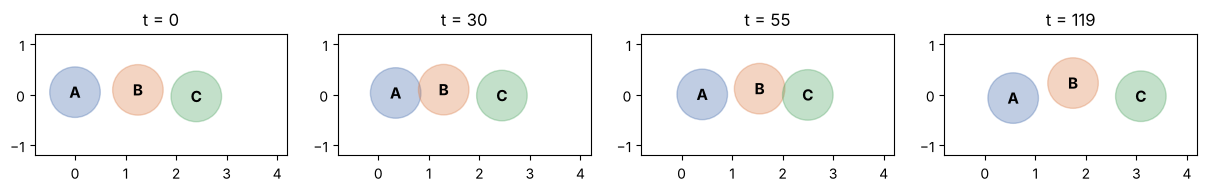

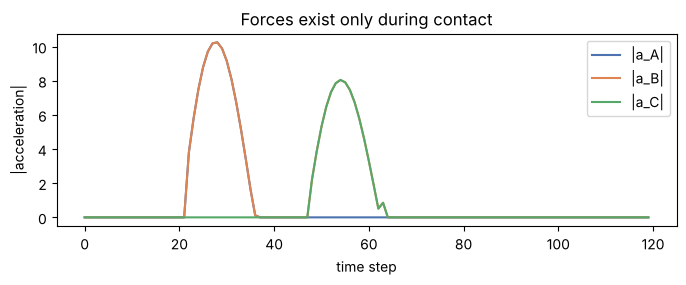

In [2]:
phys = BallParams()           # radius 0.5, k = 200, c = 2, m = 1, dt = 0.01
N_BALLS, N_STEPS = 3, 120
CONN_RADIUS = 1.2             # connectivity radius R: slightly larger than one diameter (1.0)

pos0, vel0 = random_initial_state(jax.random.PRNGKey(7), N_BALLS, phys)
demo = rollout(pos0, vel0, N_STEPS, phys)

fig, axes = plt.subplots(1, 4, figsize=(15, 2.6))
for ax, t in zip(axes, [0, 30, 55, 119]):
    viz.balls(ax, demo["pos"][t], phys.radius, xlim=(-0.8, 4.2))
    ax.set_title(f"t = {t}")
plt.show()

fig, ax = plt.subplots(figsize=(8, 2.5))
for i in range(N_BALLS):
    ax.plot(np.linalg.norm(demo["acc"][:, i], axis=-1), color=viz.BALL_COLORS[i], label=f"|a_{'ABC'[i]}|")
ax.set_xlabel("time step"); ax.set_ylabel("|acceleration|"); ax.legend(); ax.set_title("Forces exist only during contact")
plt.show()

## 2. From particles to a graph

At every time step GNS builds a graph:

* **nodes** = balls. Node features $x_i$ = the ball's velocity (GNS also uses the last 5 velocities and a material
  type; one velocity is enough here).
* **edges** = ordered pairs of balls closer than the connectivity radius $R$. Edge features $r_{ij}$ =
  displacement from sender to receiver and its length, divided by $R$. **No absolute positions**, so the model
  cannot tell where in space it is (translation invariance).

With 3 balls there are $3 \times 2 = 6$ possible directed edges (A→B, A→C, B→A, B→C, C→A, C→B).
We keep all six and use a **mask** that says which exist right now. A masked edge sends a zero message, which is
the same as it not existing.

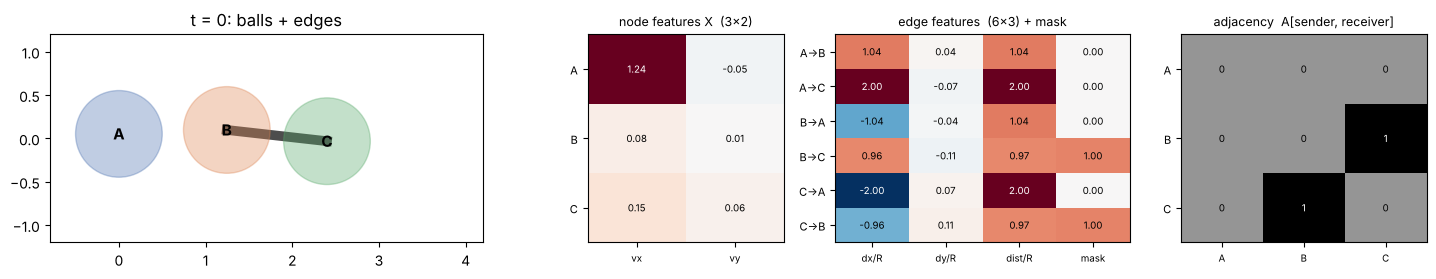

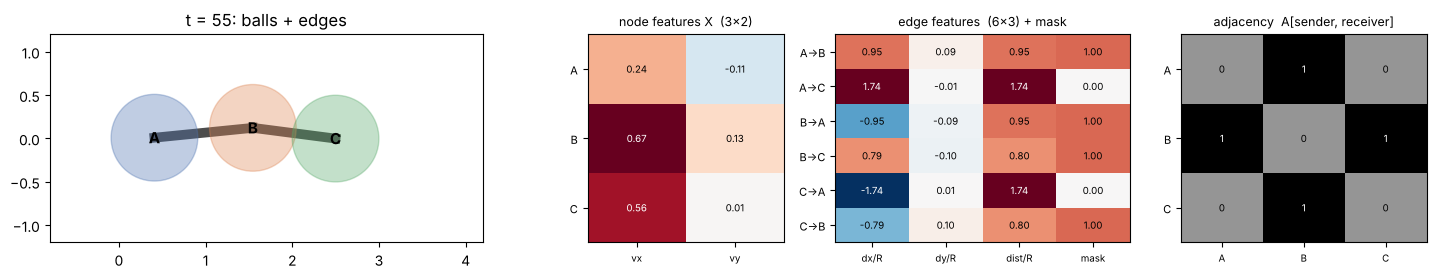

In [3]:
names = edge_names(N_BALLS)

def show_graph(t):
    g = build_graph(demo["pos"][t], demo["vel"][t], CONN_RADIUS)
    fig, axes = plt.subplots(1, 4, figsize=(15, 2.8), gridspec_kw=dict(width_ratios=[2.2, 0.8, 1.2, 1]))
    viz.balls(axes[0], demo["pos"][t], phys.radius, graph=g, xlim=(-0.8, 4.2)); axes[0].set_title(f"t = {t}: balls + edges")
    viz.matrix(axes[1], g.nodes, list("ABC"), ["vx", "vy"], "node features X  (3×2)")
    viz.matrix(axes[2], np.c_[g.edges, g.mask], names, ["dx/R", "dy/R", "dist/R", "mask"], "edge features  (6×3) + mask")
    viz.matrix(axes[3], adjacency_matrix(g, N_BALLS), list("ABC"), list("ABC"), "adjacency  A[sender, receiver]", vmax=1, fmt="{:.0f}", cmap="Greys")
    plt.tight_layout(); plt.show()

show_graph(0)    # before the collision: A and B may already be within R
show_graph(55)   # during the collision chain

### How one row of the edge matrix is computed (worked example: B→C at t = 0)

The node matrix only needs velocities. The edge matrix is where **positions** come in, and only as *differences*.
For an edge from sender $s$ to receiver $r$ (code: `src/graph.py`, `build_graph`):

$$
\Delta_{sr} = \mathbf p_r - \mathbf p_s \quad(\text{receiver minus sender}),\qquad
r_{sr} = \Big[\ \tfrac{\Delta x}{R},\ \tfrac{\Delta y}{R},\ \tfrac{|\Delta_{sr}|}{R}\ \Big],\qquad
\text{mask}_{sr} = \begin{cases}1 & |\Delta_{sr}| < R\\ 0 & \text{otherwise}\end{cases}
$$

with $R$ = `CONN_RADIUS` = 1.2. Take row **B→C** of the first figure above (t = 0). Sender B, receiver C:

| | x | y |
|---|---|---|
| $\mathbf p_B$ | 1.2447 | 0.0979 |
| $\mathbf p_C$ | 2.3999 | −0.0318 |
| $\Delta = \mathbf p_C - \mathbf p_B$ | 1.1552 | −0.1297 |
| $\Delta / R$ | **0.9627** | **−0.1080** |

* distance: $|\Delta| = \sqrt{1.1552^2 + 0.1297^2} = 1.1625$, so $|\Delta|/R = 1.1625 / 1.2 =$ **0.9687**
* mask: $1.1625 < 1.2$, so **1** (B and C are within the connectivity radius, even though they are not touching yet:
  the diameter is 1.0)

That is the row `B→C = [0.96, -0.11, 0.97 | 1]` in the plot. Three things follow directly from the formula:

* **C→B** is the same edge reversed: $\Delta$ flips sign, the distance does not, so `[-0.96, 0.11, 0.97 | 1]`.
* **A→B** has $|\Delta|/R = 1.04 > 1$, so its mask is **0**: the features are still computed, but the edge sends
  a zero message. By t = 55, A has moved closer and the same row reads 0.95 with mask 1.
* The third column is redundant with the first two ($\sqrt{(\Delta x/R)^2 + (\Delta y/R)^2}$), but GNS passes it
  anyway because it saves the MLP from having to learn a square root.

The cell below repeats the calculation with numbers straight from the simulation and checks it against
`build_graph`.

In [ ]:
t, R = 0, CONN_RADIUS
p = np.asarray(demo["pos"][t])
s, r = 1, 2                                   # sender B, receiver C
delta = p[r] - p[s]                           # receiver minus sender
dist = np.linalg.norm(delta)
row_by_hand = np.r_[delta / R, dist / R, float(dist < R)]

print(f"p_B = {p[s].round(4)},  p_C = {p[r].round(4)}")
print(f"delta = p_C - p_B = {delta.round(4)}")
print(f"|delta| = {dist:.4f},  R = {R}")
print(f"row B→C by hand  [dx/R, dy/R, dist/R, mask] = {row_by_hand.round(4)}")

g = build_graph(demo["pos"][t], demo["vel"][t], R)
e = names.index("B→C")
row_from_code = np.r_[np.asarray(g.edges[e]), float(g.mask[e])]
print(f"row B→C from build_graph                     = {row_from_code.round(4)}")
assert np.allclose(row_by_hand, row_from_code, atol=1e-5)

p_B = [1.2447 0.0979],  p_C = [ 2.3999 -0.0318]
delta = p_C - p_B = [ 1.1552 -0.1297]
|delta| = 1.1625,  R = 1.2
row B→C by hand  [dx/R, dy/R, dist/R, mask] = [ 0.9627 -0.108   0.9687  1.    ]
row B→C from build_graph                     = [ 0.9627 -0.108   0.9687  1.    ]


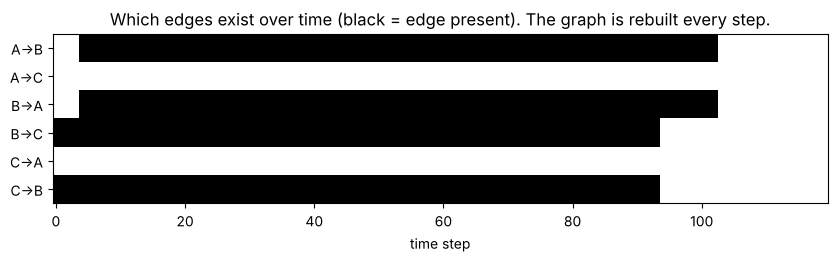

In [4]:
masks = np.stack([build_graph(demo["pos"][t], demo["vel"][t], CONN_RADIUS).mask for t in range(N_STEPS)])
fig, ax = plt.subplots(figsize=(10, 2.2))
ax.imshow(masks.T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(6)); ax.set_yticklabels(names); ax.set_xlabel("time step")
ax.set_title("Which edges exist over time (black = edge present). The graph is rebuilt every step.")
plt.show()

## 3. One forward pass, matrix by matrix

The model is **encode → process → decode** with latent size $L = 8$ and $M = 2$ message-passing steps
(GNS uses $L=128$, $M=10$).

| stage | formula | matrix shape |
|---|---|---|
| node encoder | $h_i = \text{MLP}(x_i)$ | $H$: 3 × 8 |
| edge encoder | $e_{ij} = \text{MLP}(r_{ij})$ | $E$: 6 × 8 |
| **edge function** (message) | $m_{ij} = \text{MLP}_e(e_{ij}, h_\text{sender}, h_\text{receiver})$ | 6 × 8 |
| sum at receiver (no weights) | $a_i = \sum_{j \to i} m_{ji}$ | 3 × 8 |
| **node function** | $h_i \leftarrow h_i + \text{MLP}_v(h_i, a_i)$ | 3 × 8 |
| decoder | $\ddot p_i = \text{MLP}(h_i)$ | 3 × 2 |

The **same** edge MLP runs on all 6 edges and the **same** node MLP runs on all 3 nodes. That weight sharing is
what makes it a GNN rather than a plain MLP. Below is the untrained network on one collision frame.

In [5]:
cfg = GNNConfig(latent=8, hidden=32, steps=2)
params0 = init_params(jax.random.PRNGKey(1), cfg)

t = 55
g = build_graph(demo["pos"][t], demo["vel"][t], CONN_RADIUS)
tr = apply_with_trace(params0, g)
for name, M in [("H0 (node latents)", tr.node_latent0), ("E0 (edge latents)", tr.edge_latent0),
                ("messages, step 1", tr.messages[0]), ("aggregated, step 1", tr.aggregated[0]),
                ("H after step 1", tr.node_latent[0]), ("output (acceleration, normalised)", tr.output)]:
    print(f"{name:38s} shape {tuple(M.shape)}")

H0 (node latents)                      shape (3, 8)
E0 (edge latents)                      shape (6, 8)
messages, step 1                       shape (6, 8)
aggregated, step 1                     shape (3, 8)
H after step 1                         shape (3, 8)
output (acceleration, normalised)      shape (3, 2)


## 4. Train it (and keep snapshots)

We simulate 300 random three-ball trajectories, train on one-step accelerations with Adam, and add a little
**noise to the input velocities** (the GNS trick that keeps long rollouts stable). Every 100 steps a copy of the
weights is stored, so we can look at the matrices at any point in training.

training samples: 36000


step  1000  loss 0.3075


step  2000  loss 0.0427


step  3000  loss 0.0222


step  4000  loss 0.0175


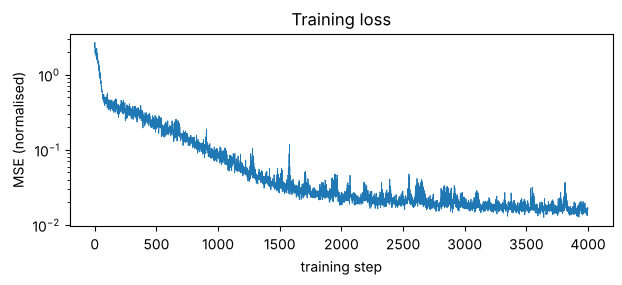

In [6]:
data = make_dataset(jax.random.PRNGKey(0), n_trajectories=300, n_steps=N_STEPS, n_balls=N_BALLS, params=phys)
norm = Normalizer.fit(data)
samples = flatten_dataset(data)
print("training samples:", samples["pos"].shape[0])

params, snapshots, snap_steps, losses = train(
    params0, samples, CONN_RADIUS, norm, phys, n_steps=4000, snapshot_every=100, log_every=1000)

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.semilogy(losses, lw=0.6); ax.set_xlabel("training step"); ax.set_ylabel("MSE (normalised)")
ax.set_title("Training loss"); plt.show()

## 5. Interactive explorer: what is inside the network, at any point of training?

Three sliders:

* **training step**: which weight snapshot to use (0 = random weights, 4000 = trained).
* **time step**: which moment of the demo trajectory is fed in.
* **message-passing step**: which of the $M = 2$ processor steps to show.

The left panel shows the balls, the edges (thicker = larger message) and the **true** (black) vs **predicted**
(red) acceleration. The matrices show the messages leaving the edge function, the per-node sums, the node latents
after the node function, and the decoded output next to the target.

Things to try:

* At training step 0 the red arrows are random. Drag the training slider and watch them lock onto the black ones.
* Pick a time step where **two balls are within R but not yet touching**: once trained, that edge's message stays
  close to "no force" even though the edge exists.
* Compare message rows **A→B** and **B→A**: the network learns that they should push in opposite directions
  (Newton's third law), without being told.

> Sliders need a live Jupyter kernel (they don't render on GitHub). A static version follows the explorer.

In [7]:
import ipywidgets as w

traces = {}
def get_trace(k, t):
    if (k, t) not in traces:
        g = build_graph(demo["pos"][t], demo["vel"][t], CONN_RADIUS, norm.vel_scale)
        traces[(k, t)] = (g, apply_with_trace(snapshots[k], g))
    return traces[(k, t)]

def explore(snapshot, t, mp_step, fixed_scale=True):
    g, tr = get_trace(snapshot, t)
    m = mp_step - 1
    msg, agg, h = tr.messages[m], tr.aggregated[m], tr.node_latent[m]
    target = demo["acc"][t] / norm.acc_scale
    vmax = 3.0 if fixed_scale else None

    fig = plt.figure(figsize=(16, 6.2))
    gs = fig.add_gridspec(2, 4, width_ratios=[2.0, 1.4, 1.4, 1.0])
    ax = fig.add_subplot(gs[0, 0])
    viz.balls(ax, demo["pos"][t], phys.radius, graph=g, edge_strength=np.linalg.norm(msg, axis=-1),
              acc_true=demo["acc"][t], acc_pred=tr.output * norm.acc_scale, acc_scale=0.03, xlim=(-0.8, 4.2))
    ax.set_title(f"training step {snap_steps[snapshot]}, t = {t}\nblack = true accel., red = predicted")
    ax = fig.add_subplot(gs[1, 0])
    ax.semilogy(losses, lw=0.5, color="0.6"); ax.axvline(snap_steps[snapshot], color="red")
    ax.set_title("loss (red line = this snapshot)", fontsize=9)

    lat = [f"l{i}" for i in range(cfg.latent)]
    viz.matrix(fig.add_subplot(gs[0, 1]), msg, names, lat, f"edge function output = messages m  (step {mp_step})", vmax)
    viz.matrix(fig.add_subplot(gs[1, 1]), agg, list("ABC"), lat, "sum of incoming messages a", vmax)
    viz.matrix(fig.add_subplot(gs[0, 2]), h, list("ABC"), lat, f"node latents h after node function (step {mp_step})", vmax)
    viz.matrix(fig.add_subplot(gs[1, 2]), g.edges * g.mask[:, None], names, ["dx/R", "dy/R", "dist/R"], "edge inputs (masked)", 1.5)
    viz.matrix(fig.add_subplot(gs[:, 3]), np.c_[tr.output, target], list("ABC"),
               ["pred x", "pred y", "true x", "true y"], "decoder output vs target\n(normalised accel.)", 3.0)
    plt.tight_layout(); plt.show()

w.interact(
    explore,
    snapshot=w.IntSlider(min=0, max=len(snapshots) - 1, value=0, description="training snap",
                         continuous_update=False, layout=w.Layout(width="500px")),
    t=w.IntSlider(min=0, max=N_STEPS - 1, value=55, description="time step", continuous_update=False,
                  layout=w.Layout(width="500px")),
    mp_step=w.IntSlider(min=1, max=cfg.steps, value=1, description="MP step"),
    fixed_scale=w.Checkbox(value=True, description="fixed colour scale"),
);

interactive(children=(IntSlider(value=0, continuous_update=False, description='training snap', layout=Layout(w…

### Static version: the same collision frame at three points in training

=== training step 0 ===


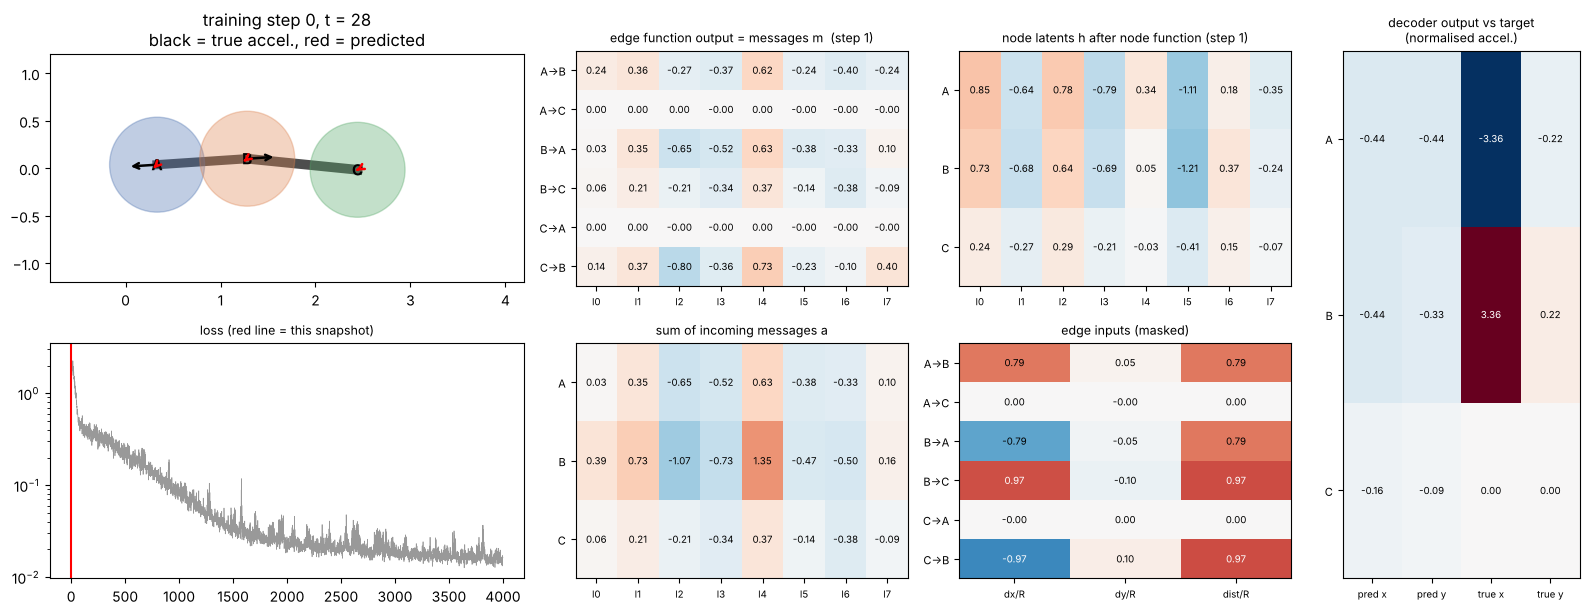

=== training step 500 ===


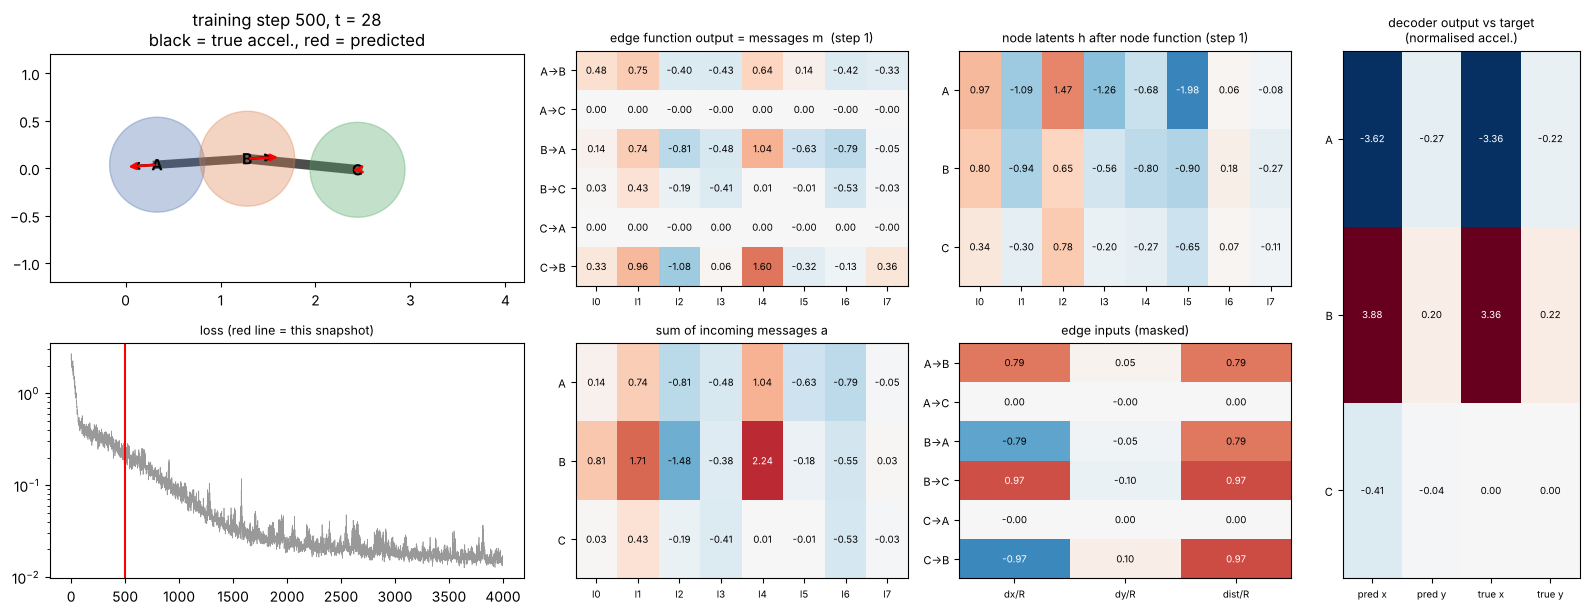

=== training step 4000 ===


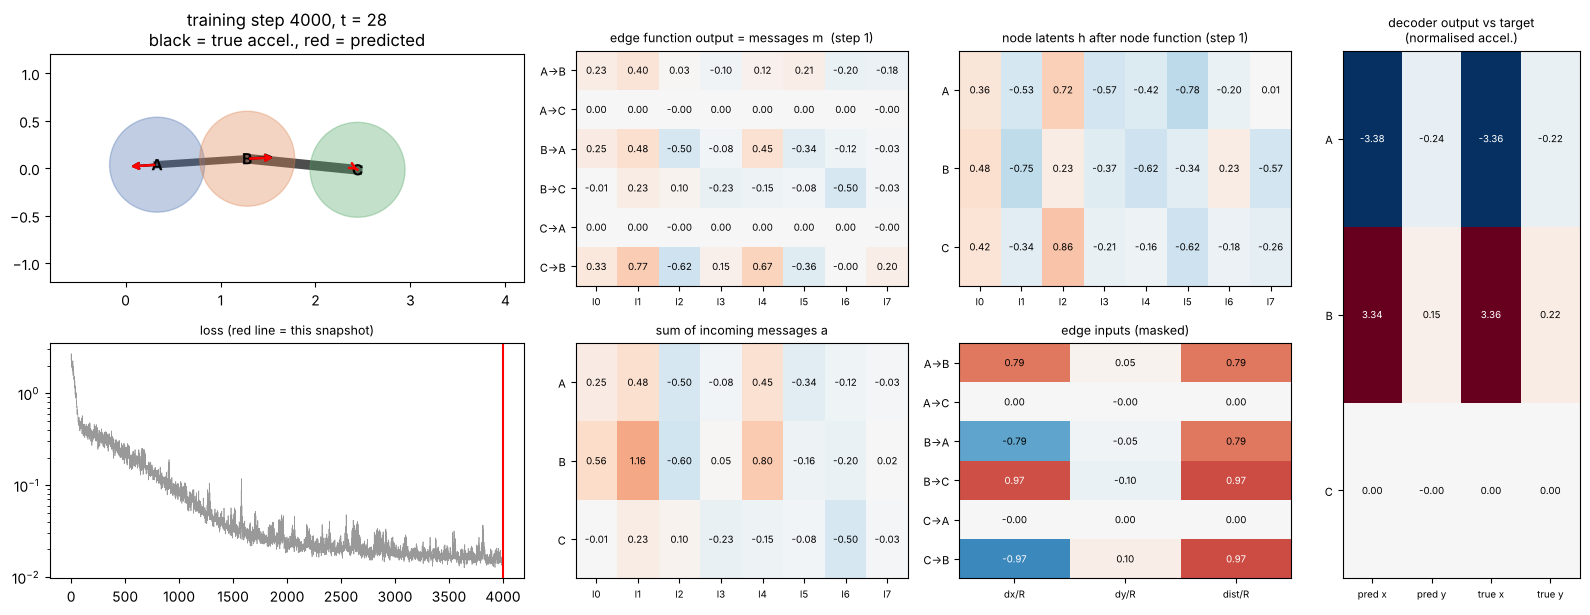

In [8]:
t_show = int(np.argmax(np.linalg.norm(demo["acc"], axis=(1, 2))))   # the frame with the strongest contact
for k in [0, 5, len(snapshots) - 1]:
    print(f"=== training step {snap_steps[k]} ===")
    explore(k, t_show, 1)

## 6. What did the edge function learn?

Take just **two** balls at rest, put B at distance $d$ to the right of A, and ask the trained GNN for B's
acceleration. The true answer is $k\cdot\max(0, 1-d)$ pushing B to the right (diameter = 1). Plotting it for
several training snapshots shows the network **discovering the contact law**: zero force beyond contact, growing
with overlap.

The model was trained on three balls but runs unchanged on two, because the same edge and node functions are
applied to whatever graph you give them.

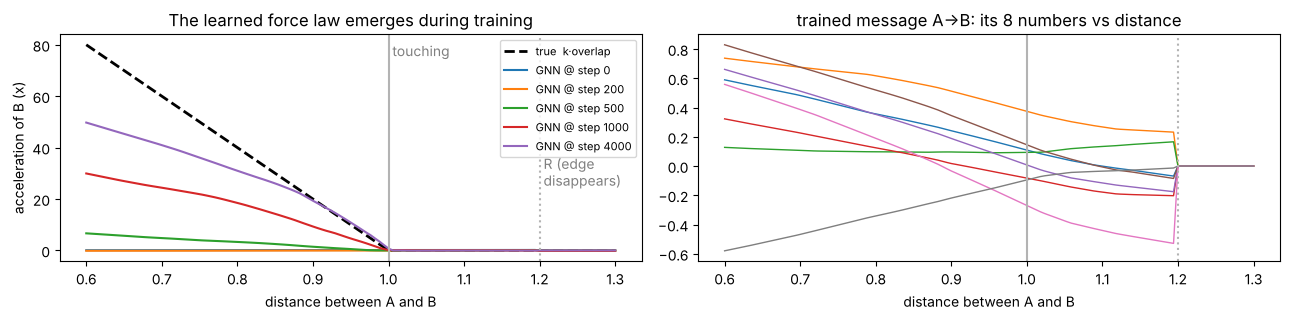

In [9]:
ds = np.linspace(0.6, 1.3, 120)
def b_accel(p, d):
    pos = jnp.array([[0.0, 0.0], [d, 0.0]]); vel = jnp.zeros((2, 2))
    return (apply_with_trace(p, build_graph(pos, vel, CONN_RADIUS, norm.vel_scale)).output * norm.acc_scale)[1, 0]
b_accel = jax.jit(jax.vmap(b_accel, in_axes=(None, 0)))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.3))
ax = axes[0]
ax.plot(ds, phys.stiffness * np.maximum(0, 1 - ds), "k--", lw=2, label="true  k·overlap")
for k in [0, 2, 5, 10, len(snapshots) - 1]:
    ax.plot(ds, b_accel(snapshots[k], jnp.asarray(ds)), label=f"GNN @ step {snap_steps[k]}")
ax.axvline(1.0, color="0.7"); ax.axvline(CONN_RADIUS, color="0.7", ls=":")
ax.text(1.0, ax.get_ylim()[1] * 0.9, " touching", color="0.5"); ax.text(CONN_RADIUS, ax.get_ylim()[1] * 0.3, " R (edge\n disappears)", color="0.5")
ax.set_xlabel("distance between A and B"); ax.set_ylabel("acceleration of B (x)"); ax.legend(fontsize=8, loc="upper right")
ax.set_title("The learned force law emerges during training")

def first_message(p, d):
    pos = jnp.array([[0.0, 0.0], [d, 0.0]]); vel = jnp.zeros((2, 2))
    return apply_with_trace(p, build_graph(pos, vel, CONN_RADIUS, norm.vel_scale)).messages[0][0]  # edge A→B
msgs = jax.vmap(first_message, in_axes=(None, 0))(params, jnp.asarray(ds))
ax = axes[1]
for i in range(cfg.latent):
    ax.plot(ds, msgs[:, i], lw=1)
ax.axvline(1.0, color="0.7"); ax.axvline(CONN_RADIUS, color="0.7", ls=":")
ax.set_xlabel("distance between A and B"); ax.set_title("trained message A→B: its 8 numbers vs distance")
plt.tight_layout(); plt.show()

**Reading the left panel.** By the end of training the GNN matches the true law closely for small overlaps
(distance 0.85 to 1.0), which is what the training collisions contained. For deeper overlaps it under-predicts:
the balls never got that close in the data, so the network never learned that part. A learned simulator is only
trustworthy inside the range of its training data.

**Reading the right panel.** This is the raw message vector on edge A→B. Its 8 numbers change smoothly with
distance and drop to exactly zero at $R = 1.2$, where the edge disappears. Notice that between 1.0 and 1.2 the
message is **not** zero, even though the true force is. The edge exists there, so the edge function still sends
something, and the node function + decoder learned to turn that "nearby but not touching" message into zero
acceleration. The network invented its own 8-number code for the interaction, and the downstream functions
learned to read it.

## 7. The trained GNN as a simulator

Now run it **autoregressively**: predict acceleration, integrate, rebuild the graph, repeat, exactly like the real
simulator. First on a new three-ball scene, then on **five balls**, a size it never saw in training.

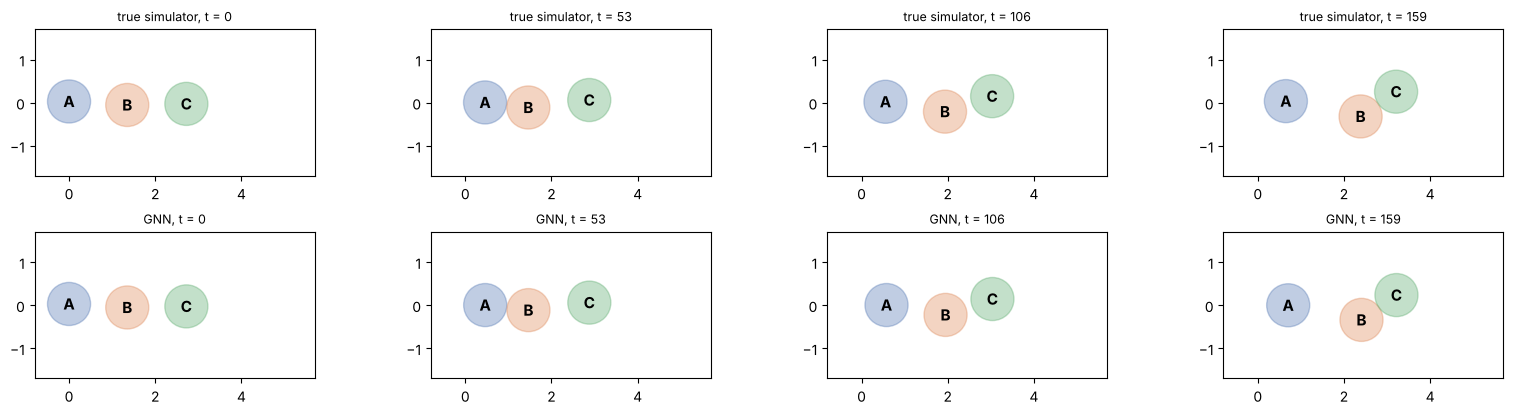

3 balls: max position error over the rollout = 0.066 (ball diameter = 1.0)


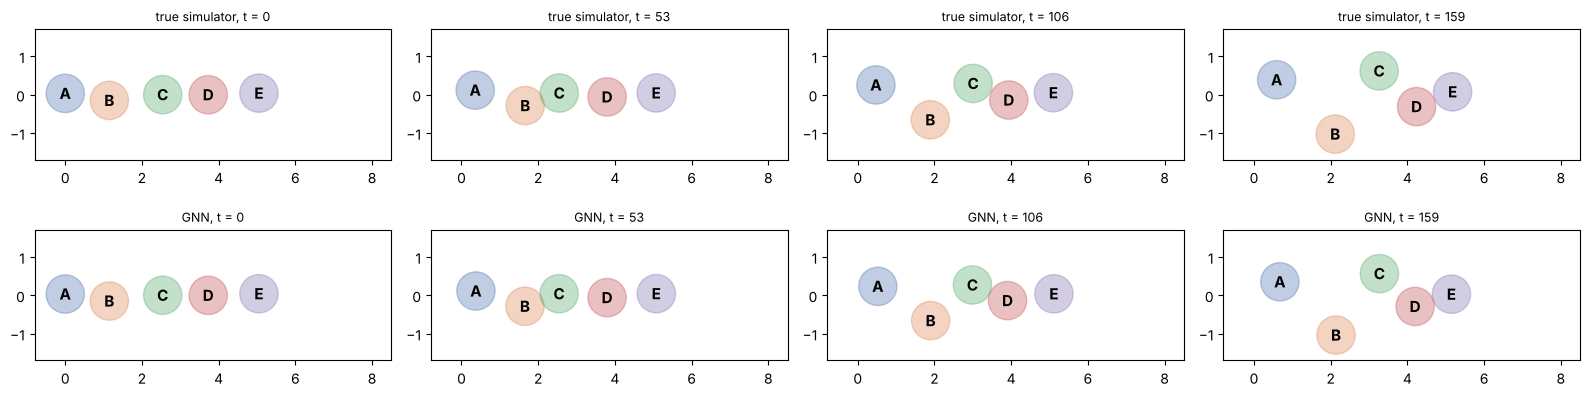

5 balls: max position error over the rollout = 0.092 (ball diameter = 1.0)


In [10]:
def compare(n_balls, seed, n_steps=160):
    p0, v0 = random_initial_state(jax.random.PRNGKey(seed), n_balls, phys)
    gt = rollout(p0, v0, n_steps, phys)
    gnn = learned_rollout(params, p0, v0, n_steps, CONN_RADIUS, norm, phys)
    fig, axes = plt.subplots(2, 4, figsize=(16, 4.2))
    for col, t in enumerate(np.linspace(0, n_steps - 1, 4).astype(int)):
        for row, (traj, name) in enumerate([(gt, "true simulator"), (gnn, "GNN")]):
            viz.balls(axes[row, col], traj["pos"][t], phys.radius, xlim=(-0.8, n_balls * 1.4 + 1.5), ylim=(-1.7, 1.7))
            axes[row, col].set_title(f"{name}, t = {t}", fontsize=9)
    plt.tight_layout(); plt.show()
    err = np.linalg.norm(np.asarray(gt["pos"] - gnn["pos"]), axis=-1).max()
    print(f"{n_balls} balls: max position error over the rollout = {err:.3f} (ball diameter = 1.0)")

compare(3, seed=2024)
compare(5, seed=11)

## Takeaways, connected to the papers

* **Graph = where to apply the network.** Edges exist only between nearby particles, and they are rebuilt every
  step.
* **Edge function = pairwise interaction.** It learned something equivalent to the contact force without seeing
  the formula.
* **Node function = response to the total.** It reads the summed messages and updates the particle, like
  Newton's second law.
* **Weight sharing** is why one model works for 2, 3 or 5 balls. GNS used it to go from 2.5k to 85k particles.
* **Paper 2 (Allen et al., 2022)** keeps exactly this kind of trained network fixed and backpropagates through
  `learned_rollout` into design parameters (e.g. where to put a wall). Every function here is differentiable,
  so `jax.grad` of a loss on the final positions with respect to the initial state works out of the box.